# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import kagglehub

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção


/Users/mfsn/Documents/cesar school/avd/AVD-20262-pratica-streamlit/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Carregando o Dataset

In [2]:
!pip install ucimlrepo --quiet
from ucimlrepo import fetch_ucirepo

path = kagglehub.dataset_download("dubradave/formula-1-drivers-dataset")
df = pd.read_csv(f"{path}/F1DriversDataset.csv")

100%|██████████| 27.9k/27.9k [00:00<00:00, 17.3MB/s]

Extracting files...


## 0. Data_Set

o Data Set escolhido foi sobre o campeonato da formula 1

Link : https://www.kaggle.com/datasets/dubradave/formula-1-drivers-dataset/data

O Formula 1 Drivers Dataset reúne informações sobre pilotos de Fórmula 1, como nacionalidade, temporadas disputadas, campeonatos, vitórias, pódios, poles, voltas mais rápidas e pontos.


*texto em itálico*## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.


### Dimensão e Tipos de Dados

In [3]:
df.shape

(868, 22)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 868 entries, 0 to 867
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Driver              868 non-null    object 
 1   Nationality         868 non-null    object 
 2   Seasons             868 non-null    object 
 3   Championships       868 non-null    float64
 4   Race_Entries        868 non-null    float64
 5   Race_Starts         868 non-null    float64
 6   Pole_Positions      868 non-null    float64
 7   Race_Wins           868 non-null    float64
 8   Podiums             868 non-null    float64
 9   Fastest_Laps        868 non-null    float64
 10  Points              868 non-null    float64
 11  Active              868 non-null    bool   
 12  Championship Years  34 non-null     object 
 13  Decade              868 non-null    int64  
 14  Pole_Rate           868 non-null    float64
 15  Start_Rate          868 non-null    float64
 16  Win_Rate

In [5]:
df.describe()

,Championships,Race_Entries,Race_Starts,Pole_Positions,Race_Wins,Podiums,Fastest_Laps,Points,Decade,Pole_Rate,Start_Rate,Win_Rate,Podium_Rate,FastLap_Rate,Points_Per_Entry,Years_Active
count,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000
mean,0.084101,29.917051,27.694700,1.244240,1.247696,3.756912,1.261521,55.849459,1972.223502,0.011471,0.779824,0.011050,0.041389,0.011894,0.479158,3.664747
std,0.524883,53.780150,52.876476,6.347512,6.491921,14.432826,5.413644,265.968614,20.201084,0.046544,0.324303,0.043579,0.106457,0.043514,1.213826,3.501761
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1960.000000,0.000000,0.666667,0.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,7.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1970.000000,0.000000,0.962251,0.000000,0.000000,0.000000,0.000000,2.000000
75%,0.000000,29.250000,26.000000,0.000000,0.000000,0.000000,0.000000,8.000000,1982.500000,0.000000,1.000000,0.000000,0.000000,0.000000,0.382517,5.000000
max,7.000000,359.000000,356.000000,103.000000,103.000000,191.000000,77.000000,4415.500000,2020.000000,0.557692,1.000000,0.461538,1.000000,0.500000,14.197749,19.000000


In [6]:
df.describe(include='all')

,Driver,Nationality,Seasons,Championships,Race_Entries,Race_Starts,Pole_Positions,Race_Wins,Podiums,Fastest_Laps,...,Championship Years,Decade,Pole_Rate,Start_Rate,Win_Rate,Podium_Rate,FastLap_Rate,Points_Per_Entry,Years_Active,Champion
count,868,868,868,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,...,34,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868.000000,868
unique,868,47,475,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,Carlo Abate,United Kingdom,[1952],NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"[2005, 2006]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
freq,1,164,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,834
mean,NaN,NaN,NaN,0.084101,29.917051,27.694700,1.244240,1.247696,3.756912,1.261521,...,NaN,1972.223502,0.011471,0.779824,0.011050,0.041389,0.011894,0.479158,3.664747,NaN
std,NaN,NaN,NaN,0.524883,53.780150,52.876476,6.347512,6.491921,14.432826,5.413644,...,NaN,20.201084,0.046544,0.324303,0.043579,0.106457,0.043514,1.213826,3.501761,NaN
min,NaN,NaN,NaN,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,NaN
25%,NaN,NaN,NaN,0.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,1960.000000,0.000000,0.666667,0.000000,0.000000,0.000000,0.000000,1.000000,NaN
50%,NaN,NaN,NaN,0.000000,7.000000,5.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,1970.000000,0.000000,0.962251,0.000000,0.000000,0.000000,0.000000,2.000000,NaN
75%,NaN,NaN,NaN,0.000000,29.250000,26.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,1982.500000,0.000000,1.000000,0.000000,0.000000,0.000000,0.382517,5.000000,NaN


### Duplicadas

In [7]:
df.duplicated().sum()

np.int64(0)

Ausencia de duplicados


## 2. Dados Faltantes

In [8]:
df.isna().sum()

Driver                  0
Nationality             0
Seasons                 0
Championships           0
Race_Entries            0
Race_Starts             0
Pole_Positions          0
Race_Wins               0
Podiums                 0
Fastest_Laps            0
Points                  0
Active                  0
Championship Years    834
Decade                  0
Pole_Rate               0
Start_Rate              0
Win_Rate                0
Podium_Rate             0
FastLap_Rate            0
Points_Per_Entry        0
Years_Active            0
Champion                0
dtype: int64

In [9]:
df[df["Championship Years"].notna()]

,Driver,Nationality,Seasons,Championships,Race_Entries,Race_Starts,Pole_Positions,Race_Wins,Podiums,Fastest_Laps,...,Championship Years,Decade,Pole_Rate,Start_Rate,Win_Rate,Podium_Rate,FastLap_Rate,Points_Per_Entry,Years_Active,Champion
17,Fernando Alonso,Spain,"[2001, 2003, 2004, 2005, 2006, 2007, 2008, 200...",2.0,359.0,356.0,22.0,32.0,99.0,23.0,...,"[2005, 2006]",2010,0.061281,0.991643,0.089136,0.275766,0.064067,5.782730,19,True
25,Mario Andretti,United States,"[1968, 1969, 1970, 1971, 1972, 1974, 1975, 197...",1.0,131.0,128.0,18.0,12.0,19.0,10.0,...,[1978],1980,0.137405,0.977099,0.091603,0.145038,0.076336,1.374046,14,True
35,Alberto Ascari,Italy,"[1950, 1951, 1952, 1953, 1954, 1955]",2.0,33.0,32.0,14.0,13.0,17.0,12.0,...,"[1952, 1953]",1950,0.424242,0.969697,0.393939,0.515152,0.363636,3.261818,6,True
107,Jack Brabham,Australia,"[1955, 1956, 1957, 1958, 1959, 1960, 1961, 196...",3.0,128.0,126.0,13.0,14.0,31.0,12.0,...,"[1959, 1960, 1966]",1960,0.101562,0.984375,0.109375,0.242188,0.093750,1.976562,16,True
135,Jenson Button,United Kingdom,"[2000, 2001, 2002, 2003, 2004, 2005, 2006, 200...",1.0,309.0,306.0,8.0,15.0,50.0,8.0,...,[2009],2010,0.025890,0.990291,0.048544,0.161812,0.025890,3.996764,18,True
169,Jim Clark,United Kingdom,"[1960, 1961, 1962, 1963, 1964, 1965, 1966, 196...",2.0,73.0,72.0,33.0,25.0,32.0,28.0,...,"[1963, 1965]",1960,0.452055,0.986301,0.342466,0.438356,0.383562,3.493151,9,True
238,Juan Manuel Fangio,Argentina,"[1950, 1951, 1953, 1954, 1955, 1956, 1957, 1958]",5.0,52.0,51.0,29.0,24.0,35.0,23.0,...,"[1951, 1954, 1955, 1956, 1957]",1950,0.557692,0.980769,0.461538,0.673077,0.442308,4.711538,8,True
239,Nino Farina,Italy,"[1950, 1951, 1952, 1953, 1954, 1955]",1.0,34.0,33.0,5.0,5.0,20.0,5.0,...,[1950],1950,0.147059,0.970588,0.147059,0.588235,0.147059,3.392059,6,True
250,Emerson Fittipaldi,Brazil,"[1970, 1971, 1972, 1973, 1974, 1975, 1976, 197...",2.0,149.0,144.0,6.0,14.0,35.0,6.0,...,"[1972, 1974]",1980,0.040268,0.966443,0.093960,0.234899,0.040268,1.885906,11,True
334,Mika Häkkinen,Finland,"[1991, 1992, 1993, 1994, 1995, 1996, 1997, 199...",2.0,165.0,161.0,26.0,20.0,51.0,25.0,...,"[1998, 1999]",2000,0.157576,0.975758,0.121212,0.309091,0.151515,2.545455,11,True


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Existem dados faltantes, Championship Years.  

Mas neste caso faz sentido os dados faltantes, a esta coluna diz os anos em que um determinado piloto ganhou um campeonato. Como só pode existir um unico campeao por ano e ele pode caganhar em multiplos anos , existem vários pilotos que não ganharam uma competição.

Como o formato de dados é [2005, 2006], indifca os anos em que o piloto ganhou vo optar por colocar percisti o NaN em caso de um piloto nao tenha ganhado o campeonato para permitir uma identificação mais facil.

Logo não sera nescessario inputar dados ou remover nessa étapa inicial.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [10]:
VARS_QUANT = [
    "Championships", "Race_Entries", "Race_Starts", "Pole_Positions",
    "Race_Wins", "Podiums", "Fastest_Laps", "Points", "Pole_Rate",
    "Start_Rate", "Win_Rate", "Podium_Rate", "FastLap_Rate",
    "Points_Per_Entry", "Years_Active"
]
VARS_QUALI = [
    "Driver", "Nationality", "Seasons", "Active", "Championship Years",
    "Decade", "Champion"
]

desc_f1 = df[VARS_QUANT].describe().T
desc_f1["skewness"] = df[VARS_QUANT].skew()
desc_f1["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_f1[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Championships,0.08,0.00,0.52,0.00,7.00,8.68,90.29
Race_Entries,29.92,7.00,53.78,1.00,359.00,2.91,9.66
Race_Starts,27.69,5.00,52.88,0.00,356.00,3.02,10.35
Pole_Positions,1.24,0.00,6.35,0.00,103.00,9.23,111.24
Race_Wins,1.25,0.00,6.49,0.00,103.00,9.82,123.57
Podiums,3.76,0.00,14.43,0.00,191.00,6.86,61.68
Fastest_Laps,1.26,0.00,5.41,0.00,77.00,7.53,75.14
Points,55.85,0.00,265.97,0.00,4415.50,9.55,117.68
Pole_Rate,0.01,0.00,0.05,0.00,0.56,6.19,49.19
Start_Rate,0.78,0.96,0.32,0.00,1.00,-1.46,0.80


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

# Resposta

A análise de assimetria e curtose mostra que o desempenho na Fórmula 1 é bastante desigual. A maioria das variáveis apresenta assimetria positiva, principalmente Championships, Pole_Positions, Race_Wins, Points e Podiums, indicando que poucos pilotos concentram os maiores valores dessas estatísticas.

Além disso, os altos valores de curtose mostram a presença de caudas pesadas e possíveis outliers. Por exemplo, Championships possui skewness de 8,68 e kurtosis de 90,29, enquanto Race_Wins apresenta skewness de 9,82 e kurtosis de 123,57. Isso mostra que existem poucos pilotos com desempenhos muito acima da maioria.

Esse comportamento é esperado em esportes de alto rendimento, já que uma pequena quantidade de pilotos consegue acumular muitos títulos, vitórias e pontos ao longo da carreira. Portanto, a distribuição dos dados não é equilibrada e apresenta uma forte concentração de valores baixos, com poucos valores muito altos puxando a distribuição para a direita.

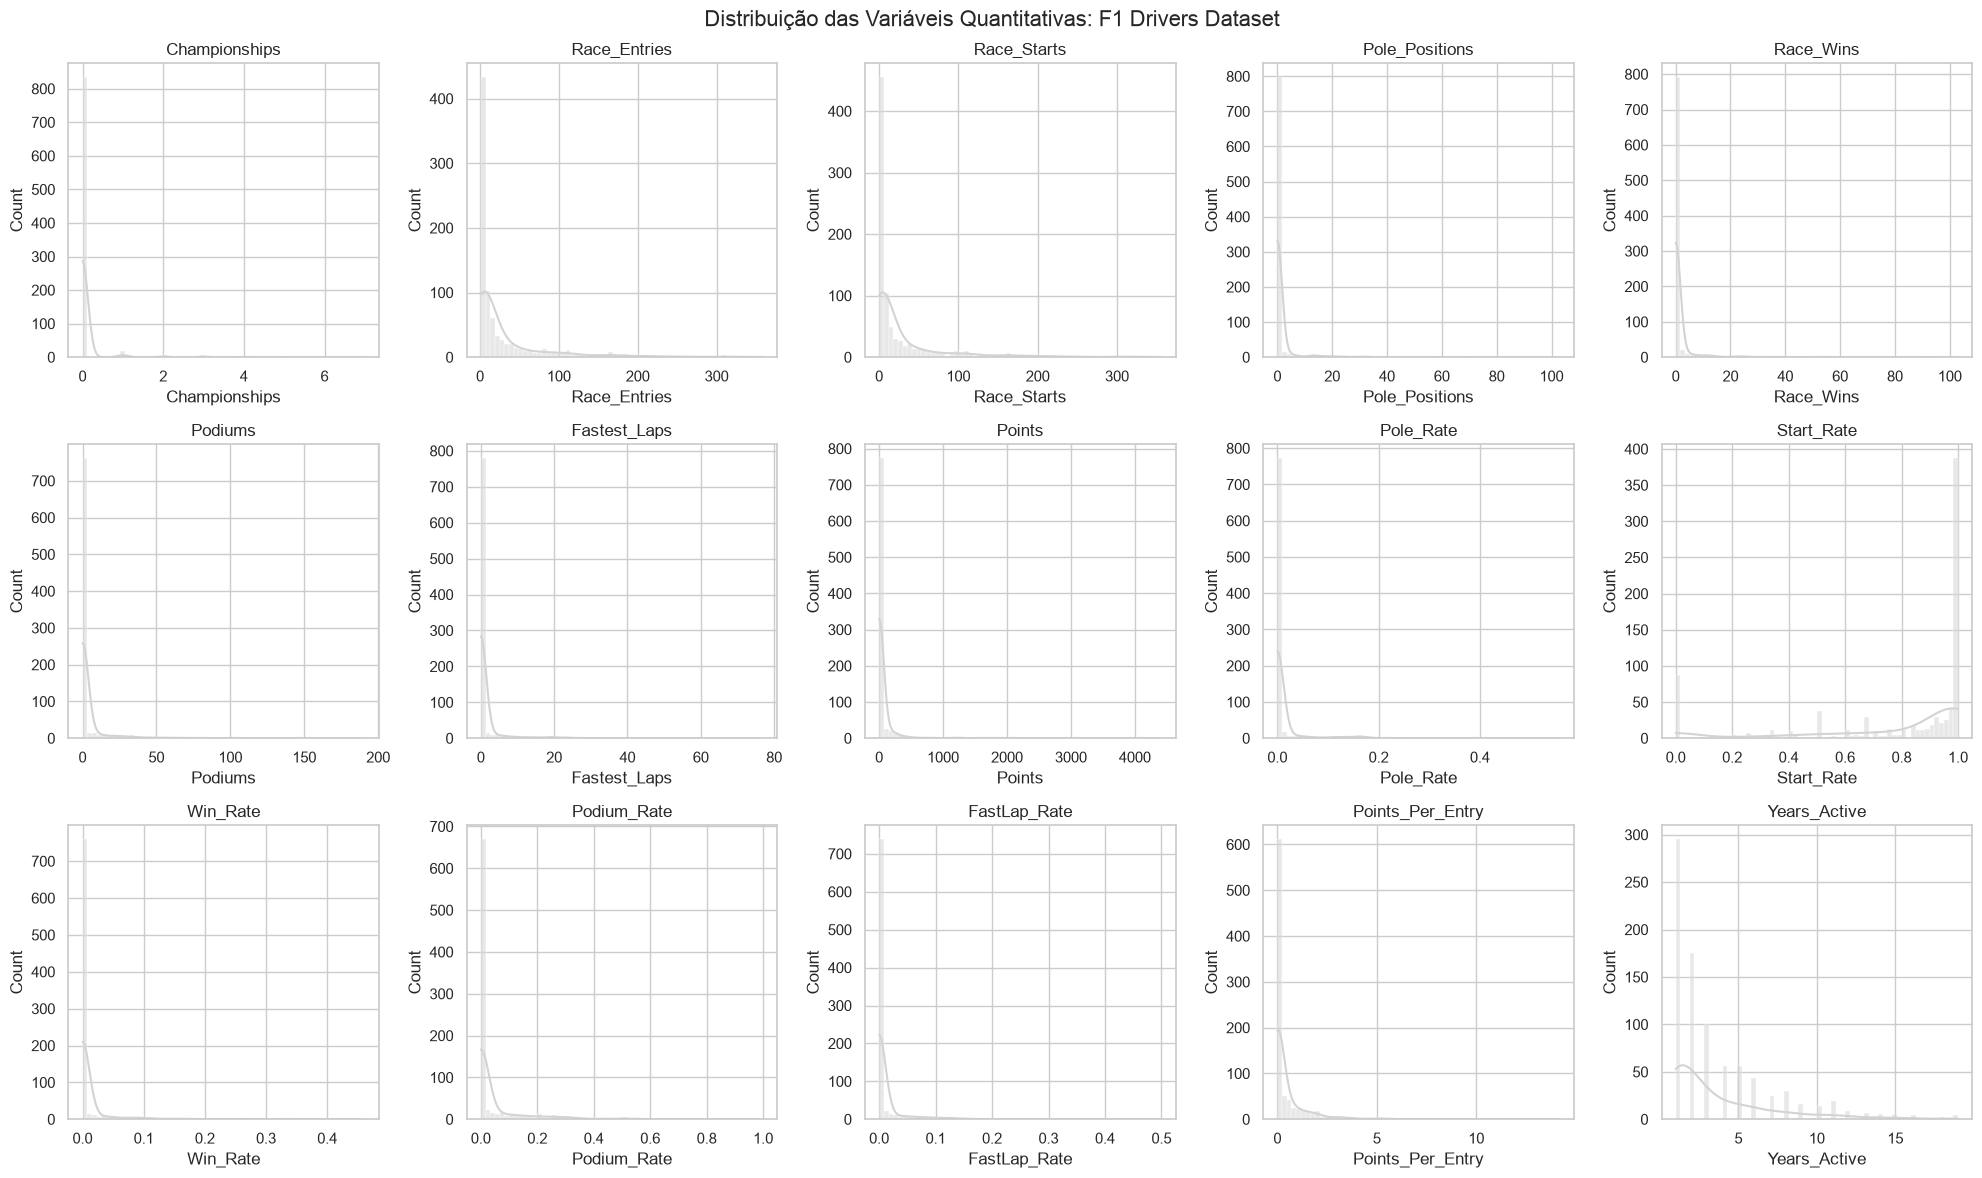

In [11]:
fig, axes = plt.subplots(3, 5, figsize=(20, 12), sharey=False)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i],bins = 60)
    axes[i].set_title(col)

fig.suptitle("Distribuição das Variáveis Quantitativas: F1 Drivers Dataset", fontsize=16)
plt.tight_layout()
plt.show()

A maioria das variáveis de desempenho na Fórmula 1 (como campeonatos, vitórias e pontos) mostra que poucos pilotos alcançam os maiores valores. Isso resulta em distribuições com cauda longa à direita e muitos *outliers*, o que ja foi apontado em analises anteriores pela kursose e simetria.

In [12]:
df["Status_Campeao"] = np.where(df["Championship Years"].notna(), "Vencedor", "Não Vencedor")

# Display the value counts for the new column and a sample of the DataFrame
print(df["Status_Campeao"].value_counts())
print("\nPrimeiras 5 linhas com a nova coluna:")
print(df[['Driver', 'Championship Years', 'Status_Campeao']].head())

Status_Campeao
Não Vencedor    834
Vencedor         34
Name: count, dtype: int64

Primeiras 5 linhas com a nova coluna:
              Driver Championship Years Status_Campeao
0        Carlo Abate                NaN   Não Vencedor
1   George Abecassis                NaN   Não Vencedor
2      Kenny Acheson                NaN   Não Vencedor
3  Andrea de Adamich                NaN   Não Vencedor
4     Philippe Adams                NaN   Não Vencedor


Como essa atividade vai ser reutilizada no futuro e era preciso ter uma coluna qualitativa combinei com ela de subistituir a tabela de Champioship Year por Vencedor e não vecendor

#### Testes de Aderência

*Sera que os pontos por corrida seguem uma distribuicao normal ? ( points per entry)*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

Shapiro-Wilk — Points_Per_Entry: estatística=0.4368, p-valor=1.055e-45
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


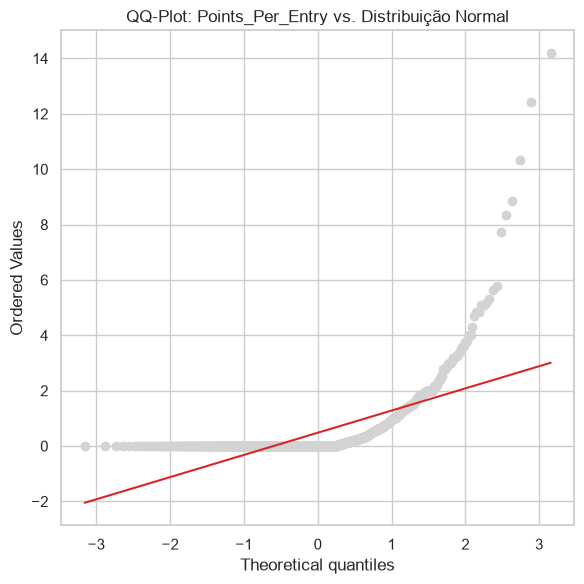

In [13]:
stat_sw, p_valor_sw = stats.shapiro(df["Points_Per_Entry"].dropna())
print(f"Shapiro-Wilk — Points_Per_Entry: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — Points_Per_Entry"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Points_Per_Entry"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Points_Per_Entry vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

A variável **Points_Per_Entry** representa a média de pontos que um piloto fez por cada entrada em corrida. O teste de Shapiro-Wilk, com um p-valor muito baixo (e-45), **rejeita a hipótese de normalidade**. Isso significa que a distribuição dos pontos por entrada não segue uma curva normal.

É possivel notar que o grafico gerado é uma exponencial o que é comprensivel dado o valor extramamente baixo do p-valor (e-45)

In [14]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Championships,0.1512,0.0,True
Race_Entries,0.5880,0.0,True
Race_Starts,0.5698,0.0,True
Pole_Positions,0.1962,0.0,True
Race_Wins,0.1893,0.0,True
Podiums,0.2817,0.0,True
Fastest_Laps,0.2469,0.0,True
Points,0.2060,0.0,True
Pole_Rate,0.2682,0.0,True


Todos os dados não seguem distribuição normal , o que faz sentido como apontado antes pelos valores da simeria e kurtose.

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.



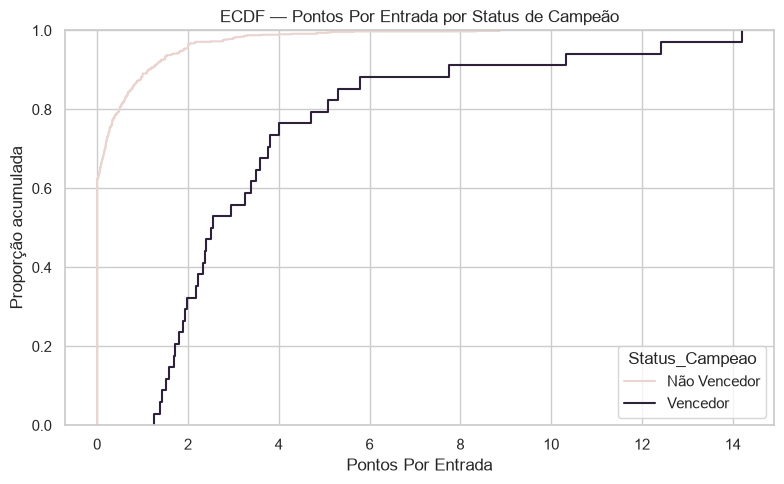

In [15]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Points_Per_Entry", hue="Status_Campeao",
             palette={"Vencedor": COR_DESTAQUE, "Não Vencedor": COR_CONTEXTO})
plt.title("ECDF — Pontos Por Entrada por Status de Campeão")
plt.xlabel("Pontos Por Entrada")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

Analise : Este gráfico ECDF mostra a distribuição acumulada de 'Pontos Por Entrada' para pilotos 'Vencedores' e 'Não Vencedores'. A diferença notável entre as curvas indica que pilotos vencedores geralmente acumulam mais pontos por entrada do que os não vencedores. Onde as curvas se separam mais, é onde a diferença entre os grupos é mais pronunciada.

### Métricas de Tendêncial Central

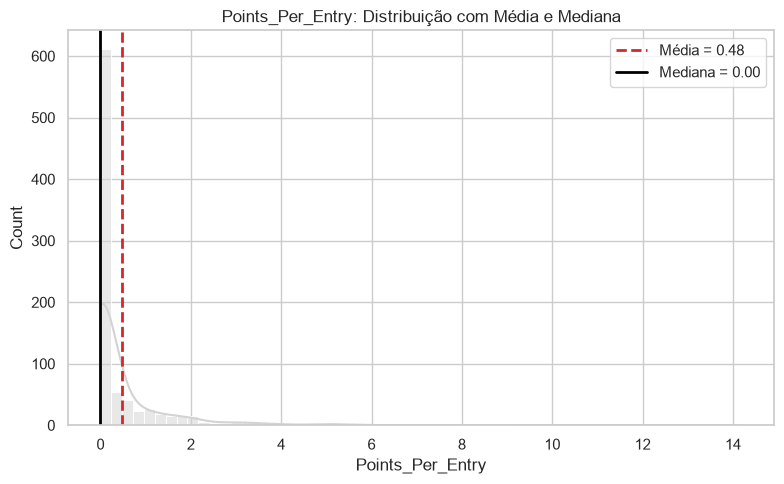

In [16]:
media_points_per_entry = df["Points_Per_Entry"].mean()
mediana_points_per_entry = df["Points_Per_Entry"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Points_Per_Entry", kde=True, color=COR_NEUTRA)
plt.axvline(media_points_per_entry, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_points_per_entry:.2f}")
plt.axvline(mediana_points_per_entry, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_points_per_entry:.2f}")
plt.title("Points_Per_Entry: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

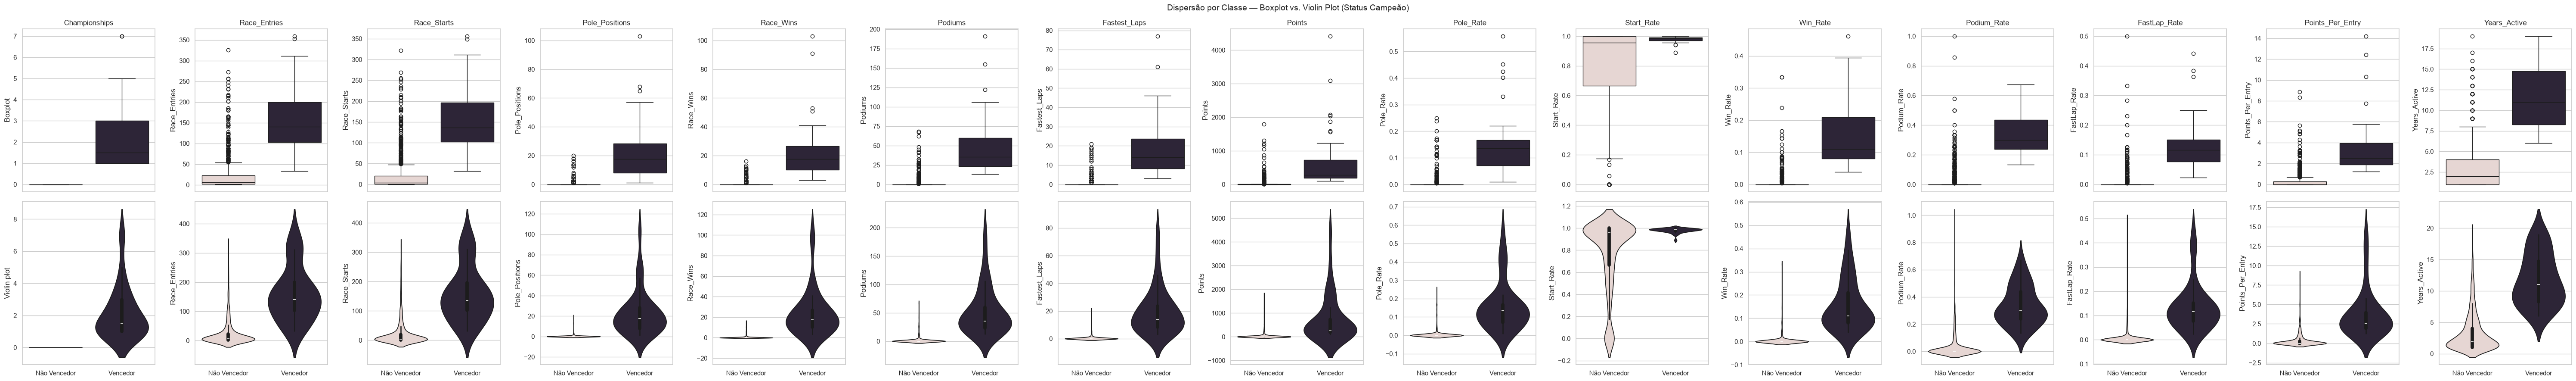

In [17]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Vencedor": COR_DESTAQUE, "Não Vencedor": COR_CONTEXTO}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="Status_Campeao", y=col, hue="Status_Campeao",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="Status_Campeao", y=col, hue="Status_Campeao",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe \u2014 Boxplot vs. Violin Plot (Status Campeão)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** Claramente existem diferenças entre campeoes e nao campeoes. É nitido observa que quando mais poles, corridas ganhas, poles, Voltas rapidas , Pontos maior a chance de um piloto ser vencedor. O que é algo intuitivo, mas tem observacoes interessantes como voltas rapidas tem muitos nao campeoes com uma quantidad maior que campeoes mas isso não implica em ser um campeão.

## 4. Tratamento de Dados Ausentes e Outliers



### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [18]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Championships,0.00,0.00,34.0
Race_Entries,-38.88,70.12,121.0
Race_Starts,-36.50,63.50,119.0
Pole_Positions,0.00,0.00,106.0
Race_Wins,0.00,0.00,113.0
Podiums,0.00,0.00,215.0
Fastest_Laps,0.00,0.00,136.0
Points,-12.00,20.00,144.0
Pole_Rate,0.00,0.00,106.0
Start_Rate,0.17,1.50,90.0


### Outliers Inferiores (abaixo do limite inferior do IQR) para todas as variáveis quantitativas

In [19]:
for col in VARS_QUANT:
    lim_inf, _ = limites_iqr(df[col])
    lower_outliers = df[df[col] < lim_inf]

    if not lower_outliers.empty:
        print(f'\nOutliers inferiores para a variável "{col}":')
        display(lower_outliers[['Driver', col, 'Status_Campeao']])
    else:
        print(f'\nNenhum outlier inferior encontrado para a variável "{col}".')



Nenhum outlier inferior encontrado para a variável "Championships".

Nenhum outlier inferior encontrado para a variável "Race_Entries".

Nenhum outlier inferior encontrado para a variável "Race_Starts".

Nenhum outlier inferior encontrado para a variável "Pole_Positions".

Nenhum outlier inferior encontrado para a variável "Race_Wins".

Nenhum outlier inferior encontrado para a variável "Podiums".

Nenhum outlier inferior encontrado para a variável "Fastest_Laps".

Nenhum outlier inferior encontrado para a variável "Points".

Nenhum outlier inferior encontrado para a variável "Pole_Rate".

Outliers inferiores para a variável "Start_Rate":


,Driver,Start_Rate,Status_Campeao
0,Carlo Abate,0.0,Não Vencedor
18,Giovanna Amati,0.0,Não Vencedor
24,Emil Andres,0.0,Não Vencedor
55,Michael Bartels,0.0,Não Vencedor
75,Enrico Bertaggia,0.0,Não Vencedor
...,...,...,...
835,Volker Weidler,0.0,Não Vencedor
841,Ted Whiteaway,0.0,Não Vencedor
851,Desiré Wilson,0.0,Não Vencedor
854,Joachim Winkelhock,0.0,Não Vencedor



Nenhum outlier inferior encontrado para a variável "Win_Rate".

Nenhum outlier inferior encontrado para a variável "Podium_Rate".

Nenhum outlier inferior encontrado para a variável "FastLap_Rate".

Nenhum outlier inferior encontrado para a variável "Points_Per_Entry".

Nenhum outlier inferior encontrado para a variável "Years_Active".


Verifiquei os outliers inferiores para consta se tinha algum que violava alguma regra de logica dos dados.

Não Existem dados que ferem outier inferiores apenas o Star_rate o que nao tem problema, Existem pilotos de formula que nunca chegaram a correr, normalmente pilotos reservas ou que foram oficialmente anunciaods mas por outro movito não chegegaram a correr.

### Visualizando os Outliers

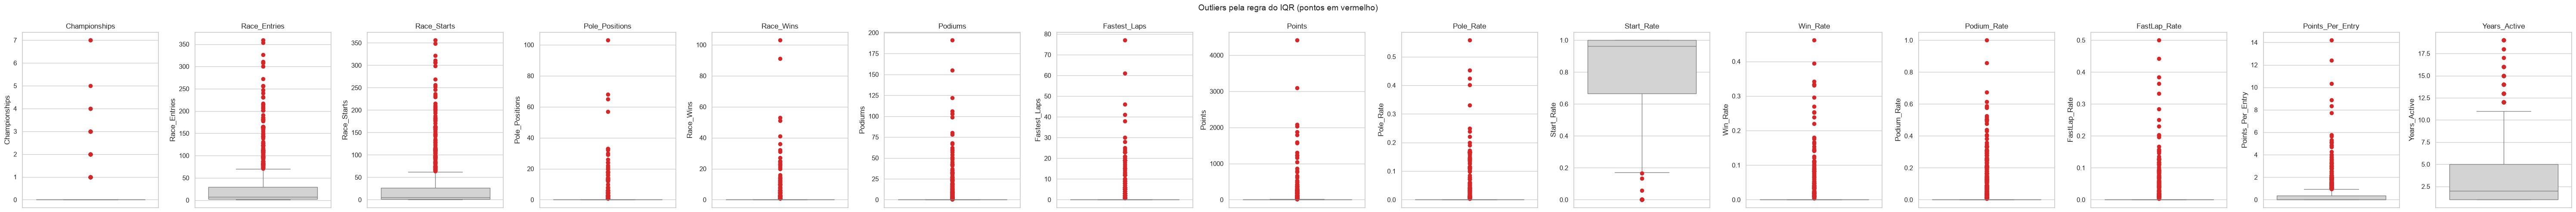

In [20]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()




Todos os outliers sao Légitimos, basicamente todos outiler sao acima do supeior. Todos eles sao legitimos e fazem parte da natureza da formula 1. Logo não faz sentido ter que subistituir algum dado.

## 5. Estatística Descritiva pt 2

Como não foi descartado nenhum dado, não faz sentido seguir com essa analise.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [21]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- Driver ---
                   absoluta  relativa
Driver                               
Carlo Abate               1     0.001
George Abecassis          1     0.001
Kenny Acheson             1     0.001
Andrea de Adamich         1     0.001
Philippe Adams            1     0.001
...                     ...       ...
Emilio Zapico             1     0.001
Zhou Guanyu               1     0.001
Ricardo Zonta             1     0.001
Renzo Zorzi               1     0.001
Ricardo Zunino            1     0.001

[868 rows x 2 columns]
\n--- Nationality ---
                            absoluta  relativa
Nationality                                   
United Kingdom                   164     0.189
United States                    160     0.184
Italy                             99     0.114
France                            72     0.083
West Germany                      39     0.045
Brazil                            32     0.037
Argentina                         25     0.029
Switzerland         


Analise :  É notável que a variável 'Champion' está bem desbalanceada, com a grande maioria dos pilotos não sendo campeões (aproximadamente 96%). Também observamos que algumas nacionalidades, como Reino Unido e Estados Unidos, têm uma frequência muito maior de pilotos. Isso é esperado em esportes como a Fórmula 1, onde o sucesso e a representatividade podem ser concentrados.

#### Visualizando as frequências

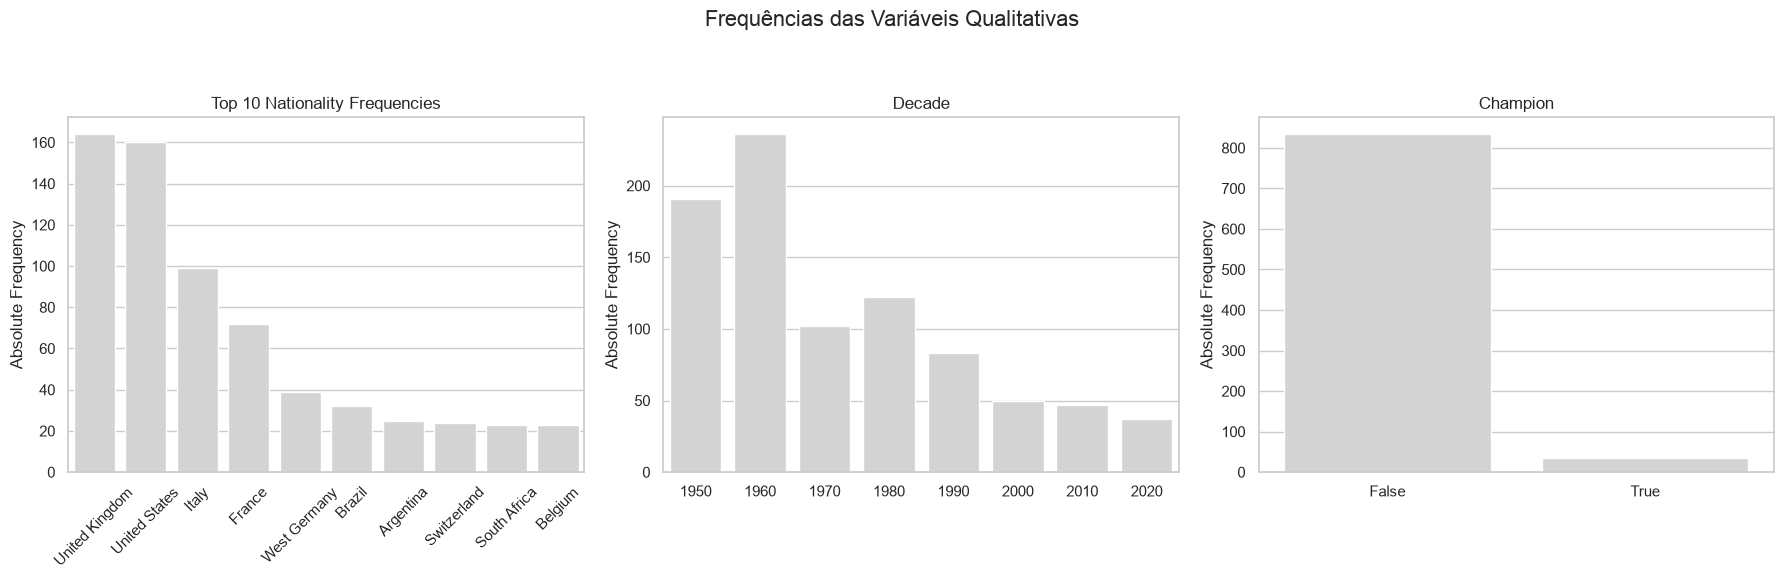

In [22]:
qualitative_vars_to_plot = ['Nationality', 'Decade', 'Champion']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, col in enumerate(qualitative_vars_to_plot):
    if col == 'Nationality':
        # For 'Nationality', show only the top 10 for better readability
        plot_data = df[col].value_counts().nlargest(10)
        sns.barplot(x=plot_data.index, y=plot_data.values, color=COR_NEUTRA, ax=axes[i])
        axes[i].set_title(f'Top 10 {col} Frequencies')
        axes[i].tick_params(axis="x", rotation=45) # Rotate labels for better fit
    else:
        # For other qualitative variables, plot all frequencies
        plot_data = df[col].value_counts().sort_index()
        sns.barplot(x=plot_data.index, y=plot_data.values, color=COR_NEUTRA, ax=axes[i])
        axes[i].set_title(col)
        axes[i].tick_params(axis="x", rotation=0)
    axes[i].set_xlabel('') # Remove x-axis label for cleaner look
    axes[i].set_ylabel('Absolute Frequency') # Add a y-axis label

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Resposta:
Sim, a variável 'Champion' é a mais desbalanceada. Quase 90% dos pilotos não são campeões. Isso é importante, pois em análises futuras, essa assimetria pode fazer com que qualquer relação com a variável 'Champion' seja dominada pela categoria 'Não Vencedor'.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.



In [23]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["Status_Campeao"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Driver,868.0,1.00,1.000
Nationality,47.0,164.00,0.733
Seasons,475.0,27.00,0.934
Active,2.0,42.40,0.158
Championship Years,34.0,1.00,1.000
Decade,8.0,6.38,0.912
Champion,2.0,24.53,0.238
Status_Campeao,2.0,24.53,0.238


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

As variaveis active, champio e status_campeeo estão desbalanceadas. O que indica que a maioria dos pilotos se encaixam em apenas uma das categorias para essas variáveis (por exemplo, a maioria não é campeã)

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

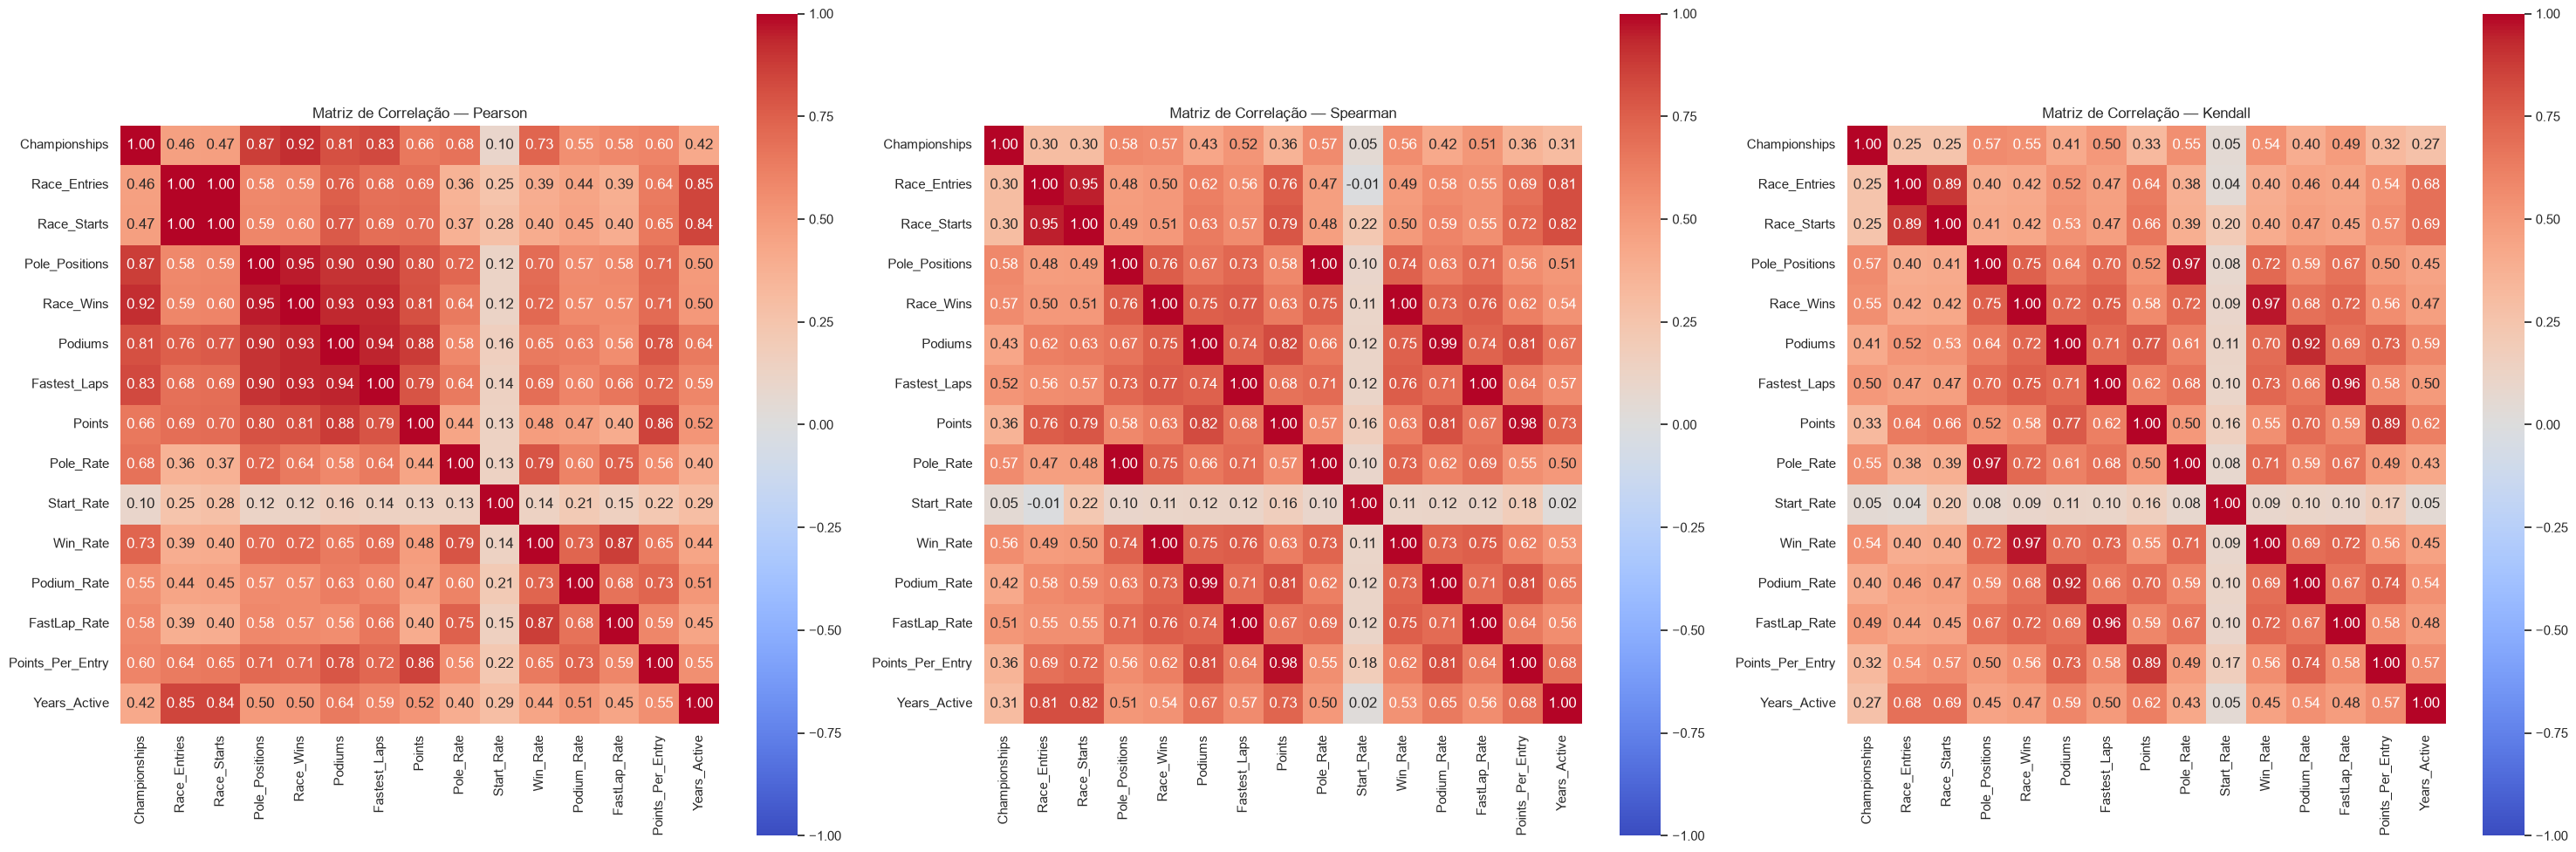

In [24]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(30, 10)) # Aumentei o tamanho da figura para melhor legibilidade
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0], square=True) # Adicionei square=True
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1], square=True) # Adicionei square=True
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2], square=True) # Adicionei square=True
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.







Resposta:

 Sim, eles divergem em algumas variáveis, por exemplo, a correlação entre 'Championships' e 'Pole_Positions' é bem diferente entre Pearson (0.87) e Spearman (0.58). Isso sugere que a relação não é perfeitamente linear, mas ainda segue uma tendência.

Analise aprofundada:


Com base na matriz de correlação de Spearman, que é adequada para nossos dados, podemos perceber algumas relações importantes:

Vitórias, Pódios e Pontos possuem uma correlação muito alta (acima de 0,90). Isso faz sentido, pois pilotos que conseguem muitas vitórias geralmente também conquistam mais pódios e pontos.
Poles também apresenta uma correlação forte (acima de 0,80) com Vitórias, Pódios e Pontos. Ou seja, pilotos que largam mais vezes na primeira posição tendem a ter melhores resultados nas corridas.
Campeonatos apresentam uma correlação forte (acima de 0,60) com as principais métricas de desempenho, chegando a 0,83 com Vitórias. Isso indica que pilotos com mais vitórias, pontos e pódios tendem a conquistar mais campeonatos.
Entradas e Largadas possuem uma correlação muito alta (0,95). Isso é esperado, já que, na maioria dos casos, um piloto que participa de mais corridas também terá mais largadas.

#### Dispersão (scatter) entre duas variáveis quantitativas

Vamos escolher 'Race_Wins' e 'Points' para visualizar a relação entre o número de vitórias em corridas e os pontos totais acumulados por um piloto. Existe uma expectativa de uma forte relação positiva entre essas duas variáveis, o que torna um bom par para visualizar uma tendência real.



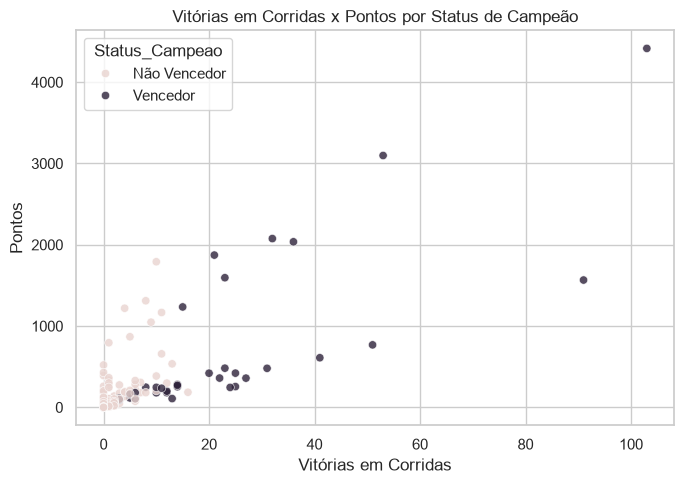

In [25]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Race_Wins", y="Points", hue="Status_Campeao",
                palette=palette_classe, alpha=0.8)
plt.title("Vitórias em Corridas x Pontos por Status de Campeão")
plt.xlabel("Vitórias em Corridas")
plt.ylabel("Pontos")
plt.tight_layout()
plt.show()

 As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

 Resposta :

 Os dois grupos, “Vencedor” e “Não Vencedor”, aparecem bem separados no gráfico. Os vencedores (roxo) estão principalmente na parte superior direita, com mais vitórias e pontos. Já os não vencedores (rosa) ficam mais na parte inferior esquerda, com menos vitórias e pontos. Isso mostra uma diferença bem clara entre os dois grupos


 Note que a quantidade de nao vencedores é bem maior que a quantidade de vencedores, pois so pode ter um campeão por ano!

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [26]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_vencedor = df.loc[df["Status_Campeao"] == "Vencedor", col]
    grupo_nao_vencedor = df.loc[df["Status_Campeao"] == "Não Vencedor", col]

    # Check if groups are empty before performing statistical tests
    if not grupo_vencedor.empty and not grupo_nao_vencedor.empty:
        stat_t, p_t = stats.ttest_ind(grupo_vencedor, grupo_nao_vencedor, equal_var=False)  # Welch (paramétrico)
        stat_u, p_u = stats.mannwhitneyu(grupo_vencedor, grupo_nao_vencedor)                 # não-paramétrico
    else:
        stat_t, p_t = np.nan, np.nan
        stat_u, p_u = np.nan, np.nan

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5) if not np.isnan(p_t) else np.nan,
        "p_valor_mannwhitney": round(p_u, 5) if not np.isnan(p_u) else np.nan,
        "concordam": (p_t < 0.05) == (p_u < 0.05) if not np.isnan(p_t) and not np.isnan(p_u) else np.nan,
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Championships,0.00000,0.00000,True
Race_Entries,0.00000,0.00000,True
Race_Starts,0.00000,0.00000,True
Pole_Positions,0.00000,0.00000,True
Race_Wins,0.00000,0.00000,True
Podiums,0.00000,0.00000,True
Fastest_Laps,0.00000,0.00000,True
Points,0.00016,0.00000,True
Pole_Rate,0.00000,0.00000,True


Os resultados mostram que, para a maioria das variáveis, como Championships, Race_Wins e Points, o p-valor foi 0.0 nos dois testes. Isso indica uma diferença muito significativa entre os grupos de “Vencedores” e “Não Vencedores”. Ou seja, os campeões apresentam valores bem maiores nessas métricas.

Porém, a variável Start_Rate apresentou um resultado diferente. O t-test deu 0.0, mas o teste de Mann-Whitney U deu 0.11082. Como nossos dados não seguem uma distribuição normal, consideramos o Mann-Whitney U mais adequado. Como 0.11082 > 0.05, não podemos dizer que existe uma diferença significativa na taxa de largada entre os dois grupos.

Em resumo: as principais métricas de desempenho diferenciam bem os campeões dos não campeões, mas a Start_Rate não apresentou uma diferença significativa entre eles.



#### Quantitativa x Qualitativa

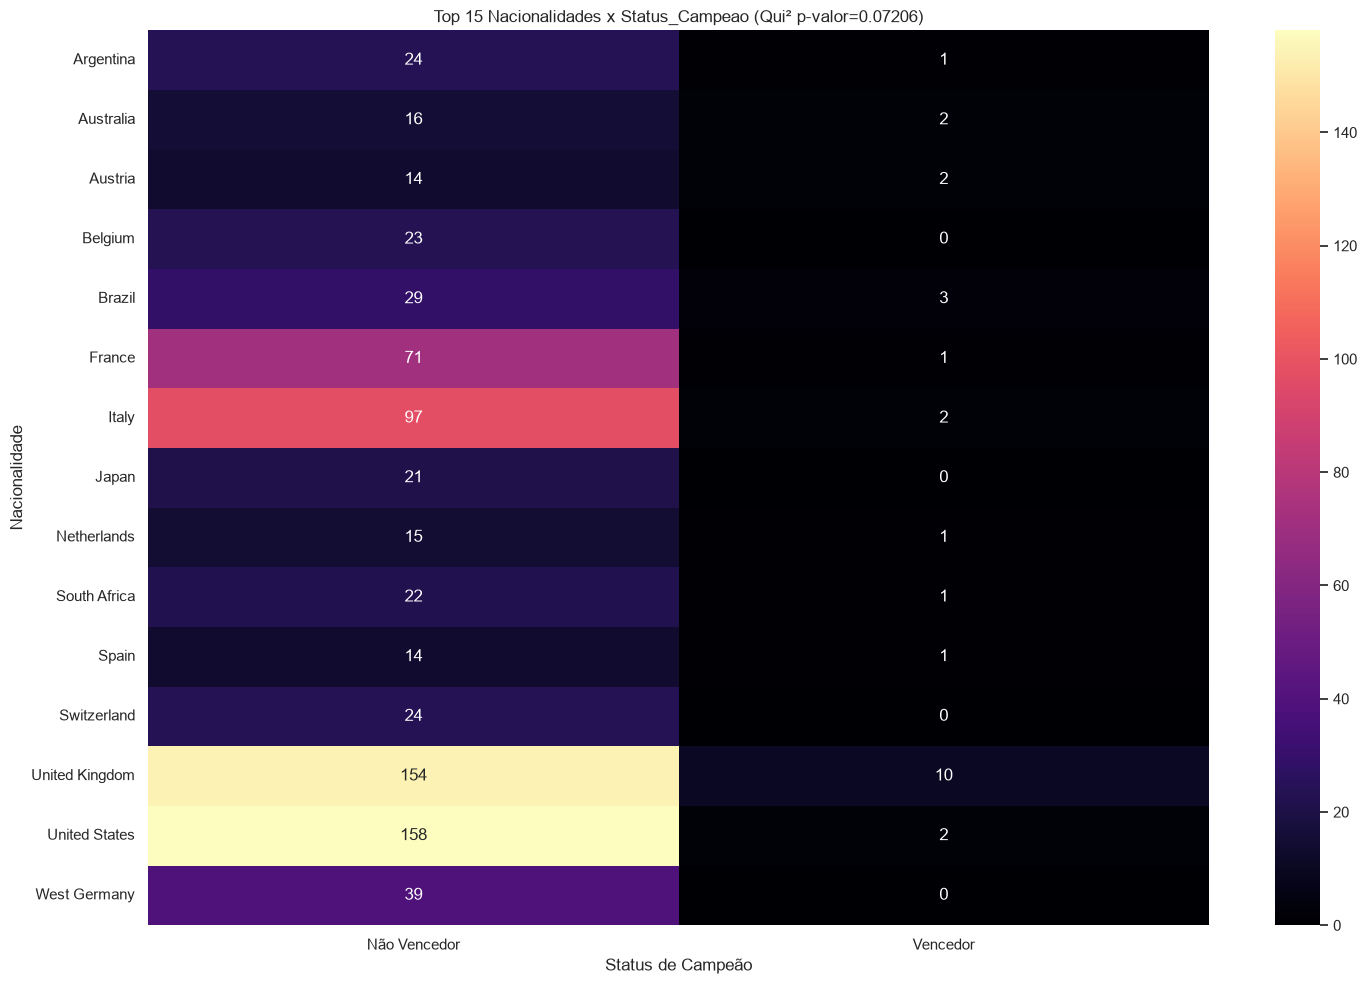

In [27]:
top_nationalities = df['Nationality'].value_counts().nlargest(15).index
df_filtered = df[df['Nationality'].isin(top_nationalities)]

contingencia_nacionalidade_status = pd.crosstab(df_filtered["Nationality"], df_filtered["Status_Campeao"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_nacionalidade_status)

fig, ax = plt.subplots(figsize=(15, 10)) # Ajustei o tamanho da figura para melhor visualização com mais países
sns.heatmap(contingencia_nacionalidade_status, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Top 15 Nacionalidades x Status_Campeao (Qui² p-valor={p_chi2:.4g})")
plt.ylabel("Nacionalidade")
plt.xlabel("Status de Campeão")
plt.tight_layout()
plt.show()

O mapa mostra a contagem de pilotos por Nacionalidade (considerando as 15 principais) e Status de Campeão. As cores mais claras representam uma maior quantidade de pilotos naquela combinação. Por exemplo, United Kingdom e United States possuem muitos pilotos na categoria “Não Vencedor”, o que é esperado devido ao grande número de pilotos dessas nacionalidades.

O teste Qui-quadrado apresentou p-valor = 0,072. Como esse valor é maior que o nível de significância de 0,05, não há evidências suficientes para afirmar que existe uma associação estatisticamente significativa entre nacionalidade e status de campeão. Ou seja, para essas 15 nacionalidades, não foi identificada uma diferença significativa na distribuição entre campeões e não campeões.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

###não faz sentido analisar a questão de fairness neste dataset de pilotos de Fórmula 1. A análise de fairness geralmente exige atributos demográficos sensíveis, como sexo, idade ou etnia, para avaliar se o desfecho se comporta de forma diferente entre subgrupos. O dataset atual não contém esses tipos de informações, tornando a análise de fairness inviável ou sem significado.

#### Outliers bivariados

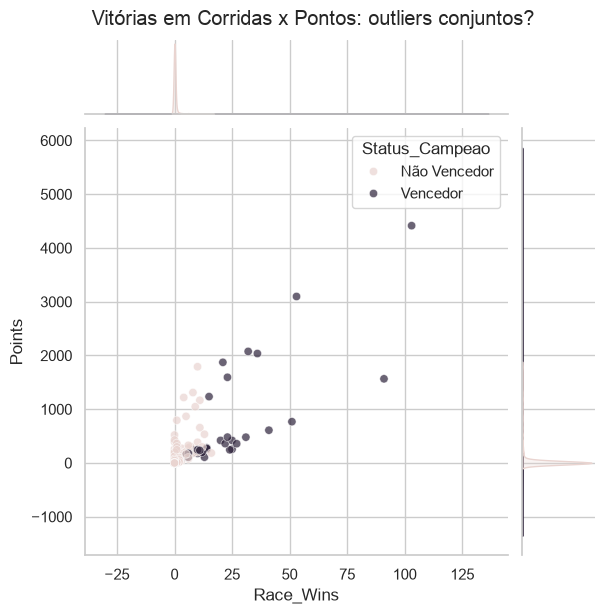

In [28]:
sns.jointplot(data=df, x="Race_Wins", y="Points", hue="Status_Campeao",
              palette=palette_classe, alpha=0.7, height=6)
plt.suptitle("Vitórias em Corridas x Pontos: outliers conjuntos?", y=1.02)
plt.show()

No gráfico atual, podemos observar que a maioria dos campeões tem um alto número de `Race_Wins` e `Points`, concentrando-se na parte superior direita. No entanto, alguns poucos pontos distantes dessa concentração, especialmente entre os 'Não Vencedores' com valores relativamente altos, podem ser considerados outliers bivariados.

Como temos poucos dados de vencedores e eles estão dispersos, quase não é possivle de visualizar o grafico dos vencedores.

#### Análise Multivariada

##### Matriz de Correlação

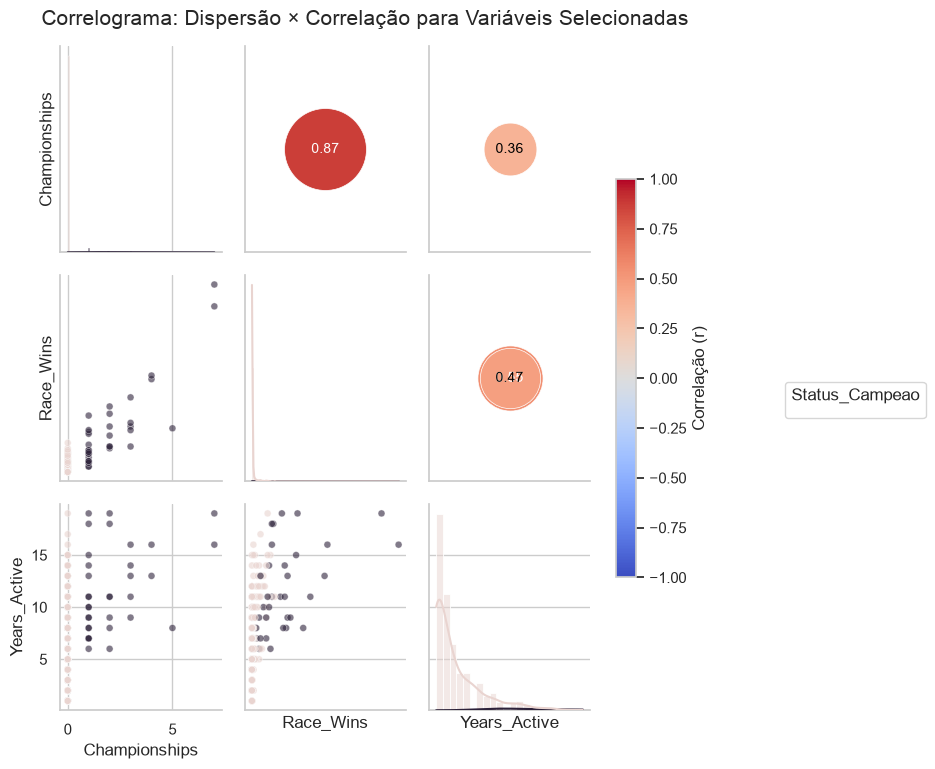

In [29]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    # Calculate correlation only if there's enough data and variance
    if len(x) > 1 and np.std(x) > 0 and np.std(y) > 0:
        r = np.corrcoef(x, y)[0, 1]
    else:
        r = np.nan # Set r to NaN if not enough data/variance

    ax = plt.gca()

    if not np.isnan(r): # Only plot if r is a valid number
        ax.scatter(
            [0.5], [0.5],
            s=abs(r) * 4000,          # tamanho proporcional à força da correlação
            c=[r], cmap='coolwarm', vmin=-1, vmax=1,
            transform=ax.transAxes, edgecolor="white", linewidth=0.5,
        )
        ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                    ha="center", va="center", fontsize=10,
                    color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

# Selecionando um subconjunto de variáveis quantitativas para um PairGrid mais legível
VARS_QUANT_SUBSET = [
    "Championships", "Race_Wins", "Years_Active"
]

g = sns.PairGrid(df, vars=VARS_QUANT_SUBSET, diag_sharey=False, hue="Status_Campeao", palette=palette_classe)
g.map_lower(sns.scatterplot, alpha=0.6, s=25)
g.map_diag(sns.histplot, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação para Variáveis Selecionadas", y=1.02, fontsize=15)

# Ajustar a legenda para fora da área do gráfico
# Obter os handles e labels de um dos subplots para criar uma legenda global da figura
handles, labels = g.axes.flat[0].get_legend_handles_labels()
# Criar a legenda diretamente na figura com posicionamento explícito
g.fig.legend(handles, labels, bbox_to_anchor=(1.05, 0.5), loc='center left', title='Status_Campeao')

# Ajustar o layout da figura para criar espaço para a legenda
g.fig.subplots_adjust(right=0.8)

plt.show()

O gráfico mostra as principais métricas do que é consicerado sucesso na formula 1.

Campeonatos, Vitórias em Corridas e Anos Ativos, estão fortemente relacionadas. Os pilotos campeões (roxo) se destacam nessas métricas, apresentando mais campeonatos, vitórias e, em geral, carreiras mais longas do que os não-vencedores (rosa). As relações entre as variáveis são predominantemente positivas e fortes, principalmente entre Campeonatos e Vitórias em Corridas, indicando que pilotos com mais vitórias tendem também a conquistar mais campeonatos.

##O uso da ia foi feita em com o intuito de auxiliar a construção de alguns graficos e ajustes em especial quando o formato sugerido na aula não atendia ao padrão do data set escolhido em especial devido a quantidade grande de colunas

##Além diso foi usado para discurti sobre o dominio dos datos para entender se os dados fazem sentido com a regra da formula 1.

##Outro uso foi para formata alguns dos textos em especial para correção de erros ótograficos.


## Download dos Datasets

Salva duas versões do dataset:

- `data/raw/dataset.csv`: o dataset **original**, como veio do Kaggle (sem a coluna `Status_Campeao`).
- `data/clean/dataset.csv`: o dataset da EDA, com a coluna `Status_Campeao`. É este arquivo que o `app.py` lê.

> Rode o notebook **do início ao fim** antes desta seção.

In [30]:
from pathlib import Path

# o notebook roda de dentro de notebooks/, por isso o ../
PASTA_RAW = Path("../data/raw")
PASTA_CLEAN = Path("../data/clean")
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [31]:
# dataset ORIGINAL, relido do Kaggle sem as alterações da EDA
df_raw = pd.read_csv(f"{path}/F1DriversDataset.csv")
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ../data/raw/dataset.csv — 868 linhas x 22 colunas


In [32]:
# dataset TRATADO (estado final do df)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")

Clean salvo em ../data/clean/dataset.csv — 868 linhas x 23 colunas
